In [25]:
import numpy as np
import pandas as pd

In [22]:
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score

from sklearn.preprocessing import KBinsDiscretizer
from sklearn. compose import ColumnTransformer

from sklearn.model_selection import cross_val_score
from sklearn.tree import DecisionTreeClassifier

In [10]:
df = pd.read_csv(r"C:\Users\roypr\Downloads\train.csv",usecols=['Age','Fare','Survived'])

In [11]:
df.dropna(inplace=True)

In [12]:
df.shape

(714, 3)

In [13]:
df.head()

,Survived,Age,Fare
0,0,22.0,7.2500
1,1,38.0,71.2833
2,1,26.0,7.9250
3,1,35.0,53.1000
4,0,35.0,8.0500


In [14]:
X = df.iloc[:,1:]
y = df.iloc[:,0]

In [15]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=0)

In [17]:
X_train.head(2)

,Age,Fare
387,36.0,13.0000
685,25.0,41.5792


In [18]:
clf = DecisionTreeClassifier()

In [19]:
clf.fit(X_train,y_train)
y_pred = clf.predict(X_test)

In [20]:
accuracy_score(y_test,y_pred)

0.6223776223776224

In [26]:
np.mean(cross_val_score(DecisionTreeClassifier(),X,y,cv=10,scoring = 'accuracy'))

np.float64(0.6330985915492957)

In [27]:
kbin_age = KBinsDiscretizer(n_bins=5,encode='ordinal',strategy='kmeans')
kbin_fare = KBinsDiscretizer(n_bins=5,encode='ordinal',strategy='kmeans')

In [28]:
trf = ColumnTransformer([('first',kbin_age,[0]),
                         ('second',kbin_fare,[1])])

In [29]:
X_train_trf = trf.fit_transform(X_train)
X_test_trf = trf.transform(X_test)

In [33]:
trf.named_transformers_['second'].n_bins_


array([5])

In [31]:
trf.named_transformers_['first'].bin_edges_

array([array([ 0.67      , 13.04912869, 26.44241242, 39.17080583, 54.420313  ,
              80.        ])                                                   ],
      dtype=object)

In [34]:
output = pd.DataFrame({
'age':X_train['Age'],
'age_trf':X_train_trf[:,0],
'fare':X_train['Fare'],
'fare_trf':X_train_trf[:,1]
})

In [35]:
output['age_labels'] = pd.cut(x=X_train['Age'],
bins=trf.named_transformers_['first'].bin_edges_[0].tolist())
output['fare_labels'] = pd.cut(x=X_train['Fare'],
bins=trf.named_transformers_['second'].bin_edges_[0].tolist())

In [37]:
output.sample(5)

,age,age_trf,fare,fare_trf,age_labels,fare_labels
510,29.0,2.0,7.750,0.0,"(26.442, 39.171]","(0.0, 40.61]"
290,26.0,1.0,78.850,1.0,"(13.049, 26.442]","(40.61, 96.281]"
744,31.0,2.0,7.925,0.0,"(26.442, 39.171]","(0.0, 40.61]"
841,16.0,1.0,10.500,0.0,"(13.049, 26.442]","(0.0, 40.61]"
587,60.0,4.0,79.200,1.0,"(54.42, 80.0]","(40.61, 96.281]"


In [38]:
clf = DecisionTreeClassifier()
clf.fit(X_train_trf,y_train)
y_pred2 = clf.predict(X_test_trf)

In [39]:
accuracy_score(y_test,y_pred2)

0.6783216783216783

In [40]:
X_trf = trf.fit_transform(X)
np.mean(cross_val_score(DecisionTreeClassifier(),X_trf,y,cv=10,scoring = 'accuracy'))

np.float64(0.6723982785602504)

In [41]:
X_trf = trf.fit_transform(X)
np.mean(cross_val_score(DecisionTreeClassifier(),X,y,cv=10,scoring='accuracy'))

np.float64(0.6344874804381847)

In [43]:
def discretize(bins,strategy):
    kbin_age = KBinsDiscretizer(n_bins=bins,encode='ordinal',strategy=strategy)
    kbin_fare = KBinsDiscretizer(n_bins=bins, encode='ordinal', strategy=strategy)

    trf = ColumnTransformer([
    ('first',kbin_age,[0]),
    ('second',kbin_fare, [1])
    ])

    X_trf = trf.fit_transform(X)
    print(np.mean(cross_val_score(DecisionTreeClassifier(),X,y,cv=10,scoring='accuracy')))

    plt.figure(figsize=(14,4))
    plt.subplot(121)
    plt.hist(X['Age'])
    plt.title("Before")

    plt.subplot(122)
    plt.hist(X_trf[:,0],color='red')
    plt.title("After")

    plt.show()

0.6288732394366197


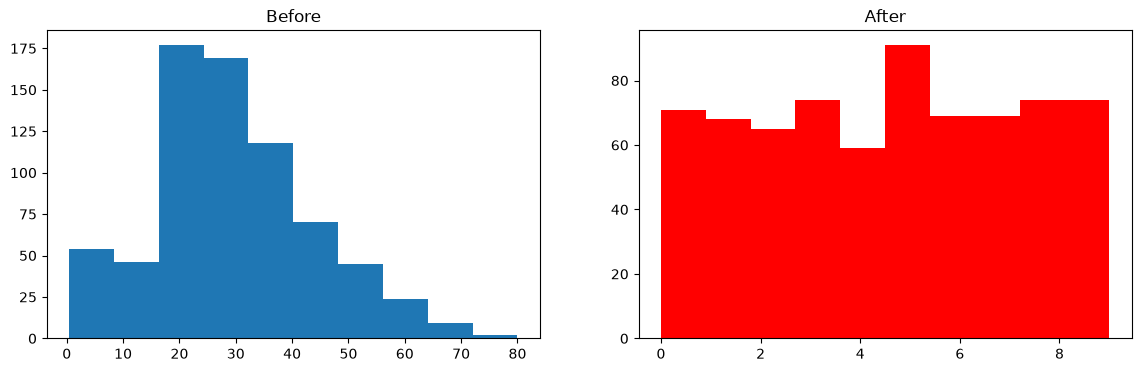

In [44]:
discretize(10,'quantile')